In [1]:
import sys
import os
import pickle
import numpy as np
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils import read_utils
from utils import read_utils_nwb

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(read_utils_nwb)

<module 'utils.read_utils_nwb' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer-(flygenvector)/data_exploration/../utils/read_utils_nwb.py'>

In [3]:
read_ids = list(range(0, 13+1))
# read_ids = [3]
plot_id = 3

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer-(flygenvector)')

file_ids, filenames, dicts = read_utils.get_data(os.path.join(path, 'pickle'), read_ids)

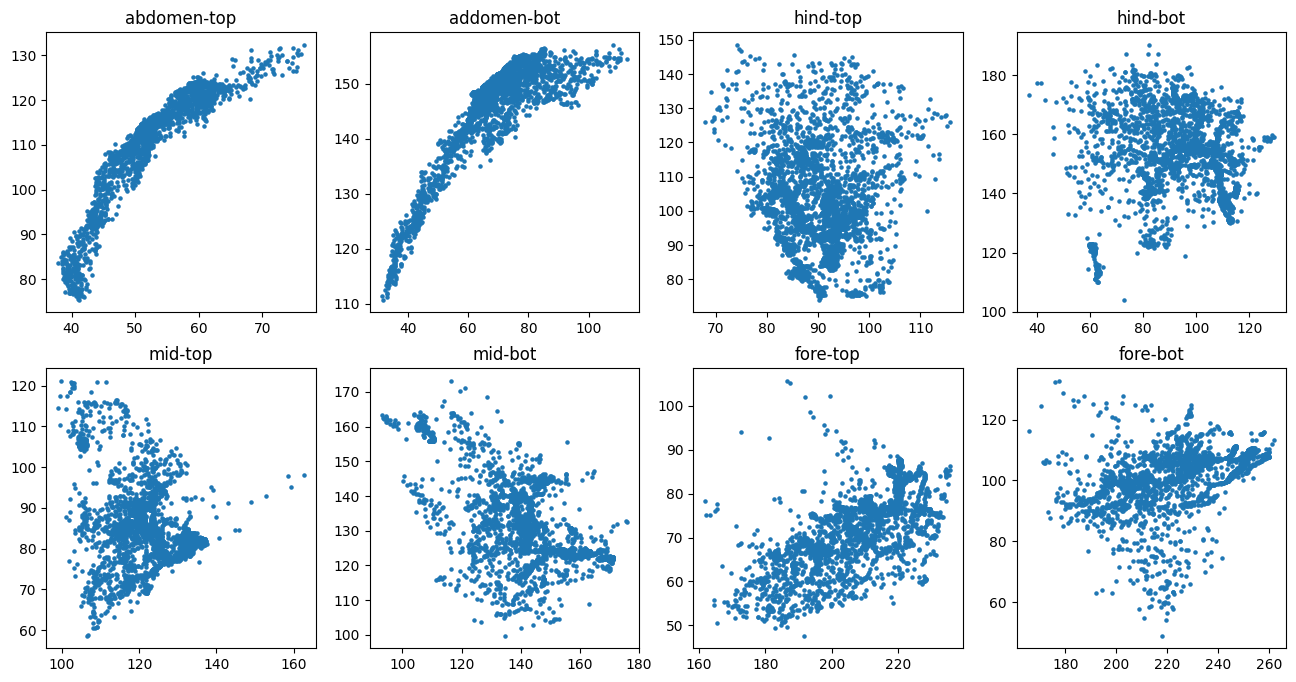

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx in range(8):
	axes[idx // 4, idx % 4].scatter(dicts[file_ids.index(plot_id)]['beh_markers_x'][:, idx], dicts[file_ids.index(plot_id)]['beh_markers_y'][:, idx], s=5)
	axes[idx // 4, idx % 4].set_title(dicts[file_ids.index(plot_id)]['marker_names'][idx])

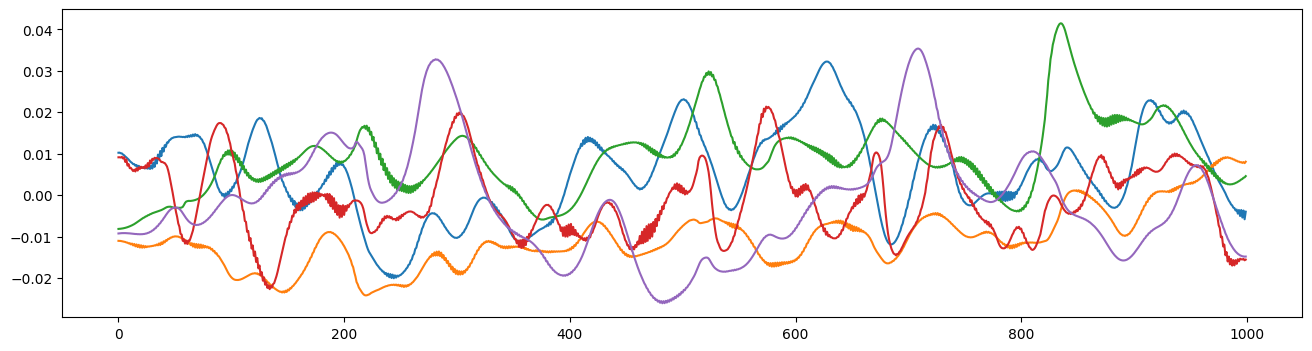

In [6]:
plt.figure(figsize=(16, 4))
plt.plot(dicts[file_ids.index(plot_id)]['dFF'].T[:1000, :5])

In [7]:
path = os.path.join(path)
(file_ids, filenames,
 traces,
 ball_motions,
 behavioral_states) = read_utils_nwb.get_data(os.path.join(path, 'nwb'))

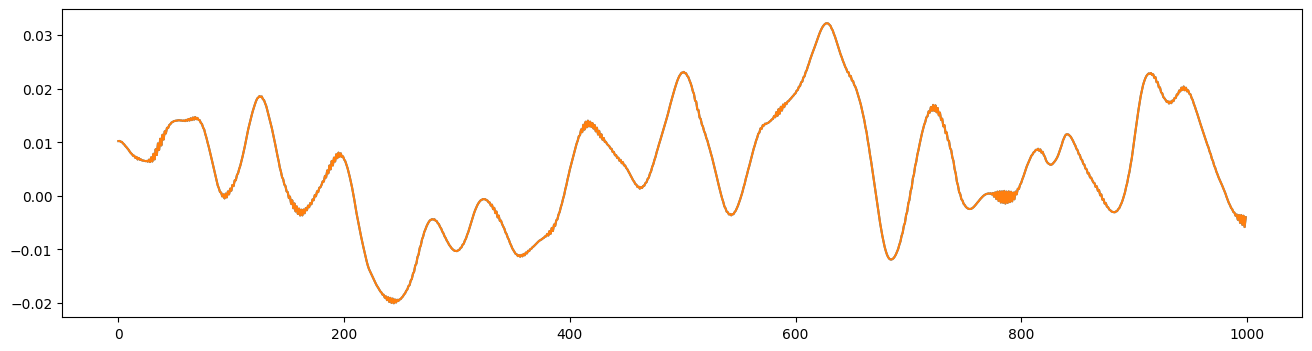

In [13]:
plt.figure(figsize=(16, 4))
plt.plot(dicts[file_ids.index(plot_id)]['dFF'].T[:1000, 0])
plt.plot(traces[file_ids.index(plot_id)].values[:1000, 0])

In [16]:
for file_id in file_ids:
	print(dicts[file_ids.index(file_id)]['dFF'].T.shape)
	print(traces[file_ids.index(file_id)].values.shape, '\n')

(10219, 1559)
(10219, 1559) 

(19083, 1688)
(19083, 1688) 

(7671, 1202)
(7671, 1202) 

(5598, 1146)
(5598, 1146) 

(16206, 874)
(16206, 874) 

(19095, 851)
(19095, 851) 

(14355, 1648)
(14355, 1648) 

(12657, 1811)
(12657, 1811) 

(11408, 1095)
(11408, 1095) 

(8533, 1672)
(8533, 1672) 

(19089, 1171)
(19089, 1171) 

(12653, 883)
(12653, 883) 

(15871, 1134)
(15871, 1134) 

(9438, 1316)
(9438, 1316) 



TODO: what does it mean for the nwb data to have a state vector of only 0's?

In [38]:
for file_id in file_ids:
	states_raw = np.argmax(dicts[file_ids.index(file_id)]['beh_labels'], axis=1)
	states = np.argmax(behavioral_states[file_ids.index(file_id)].values, axis=1)

	print(file_id)
	print(states_raw - states <= 1E0)
	print(np.sum(states_raw - states))

	print(np.where((states_raw - states) != 0))


0
[ True  True  True ...  True  True  True]
578
(array([ 168,  184,  217,  251,  261,  339,  340,  509,  510,  515,  560,
        587,  590,  750,  852,  853,  861, 1052, 1053, 1099, 1263, 1286,
       1400, 1478, 1481, 1482, 1621, 1622, 1627, 1671, 1703, 1712, 1713,
       1714, 1715, 1727, 1729, 1909, 2002, 2118, 2254, 2255, 2256, 2314,
       2315, 2316, 2317, 2320, 2321, 2322, 2324, 2339, 2340, 2345, 2349,
       2650, 3015, 3116, 3118, 3119, 3182, 3202, 3223, 3224, 3225, 3226,
       3373, 3380, 3381, 3387, 3388, 3394, 3428, 3495, 3527, 3528, 3653,
       3739, 3748, 3752, 3755, 3757, 3855, 3856, 3994, 3996, 4092, 4095,
       4211, 4214, 4231, 4256, 4296, 4440, 4444, 4578, 4579, 4630, 4634,
       4638, 4666, 4690, 4740, 4985, 5002, 5003, 5033, 5277, 5301, 5302,
       5303, 5309, 5310, 5316, 5328, 5347, 5348, 5349, 5350, 5443, 5537,
       5575, 5576, 5594, 5598, 5620, 5679, 5682, 5725, 5850, 5855, 5864,
       5866, 5872, 5992, 6021, 6024, 6039, 6045, 6090, 6091, 6406, 6407,
  

In [55]:
id = 560

# print(file_ids.index(0))

print(dicts[file_ids.index(0)]['beh_labels'][id])
print(np.argmax(dicts[file_ids.index(0)]['beh_labels'][id]))

print(behavioral_states[file_ids.index(0)].values[id])
print(np.argmax(behavioral_states[file_ids.index(0)].values[id]))

[1.30370893e-07 1.15964147e-04 4.54836339e-01 1.11438806e-06
 1.37252972e-01 4.07793432e-01]
2
[0 0 0 0 0 0]
0
